In [1355]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [1356]:
df=pd.read_csv('diabetes.csv')
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [1357]:
df.tail()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1
767,1,93,70,31,0,30.4,0.315,23,0


In [1358]:
df.shape

(768, 9)

In [1359]:
df.size

6912

In [1360]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [1361]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [1362]:
df.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='str')

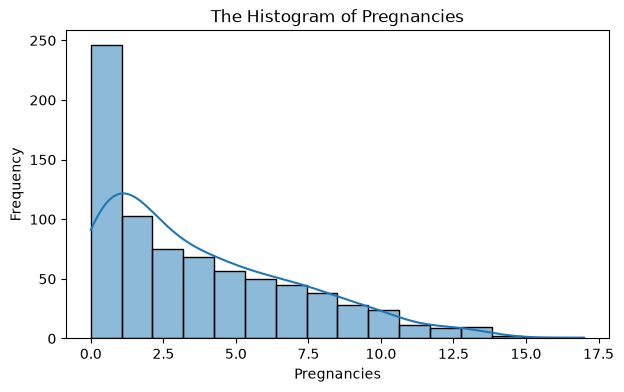

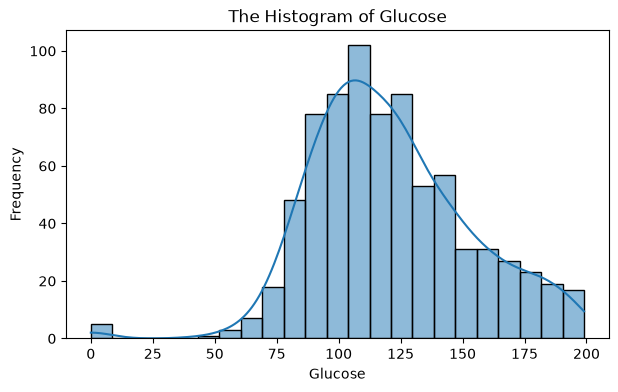

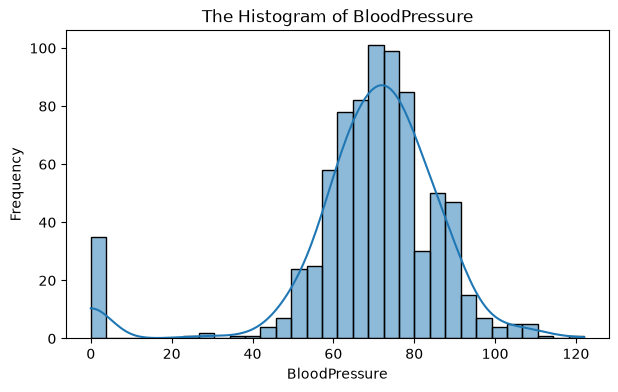

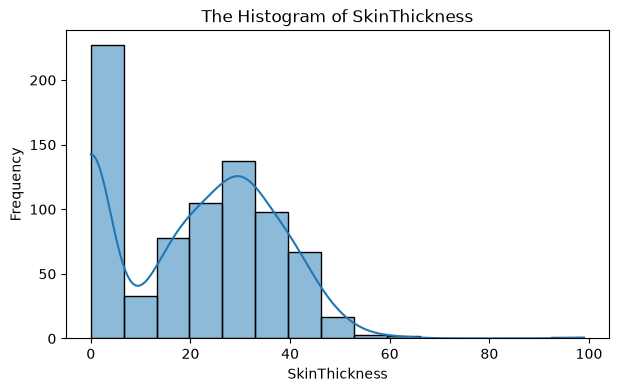

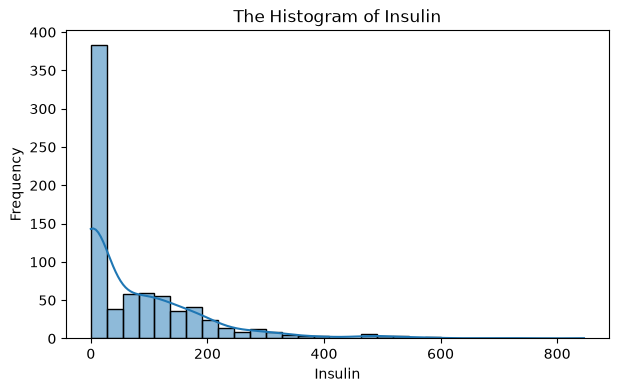

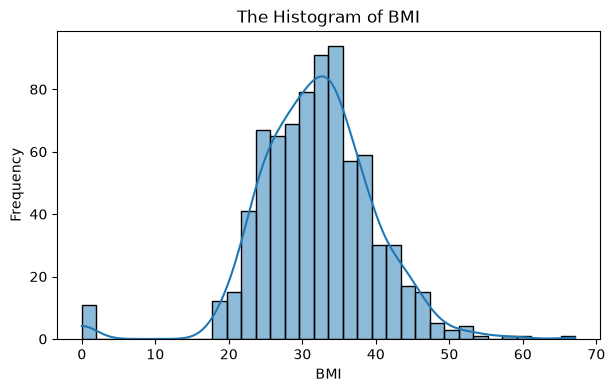

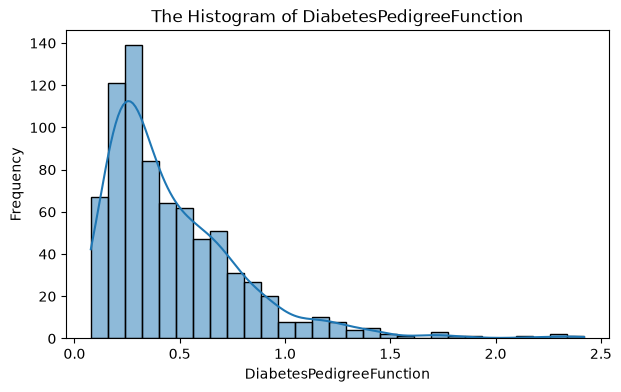

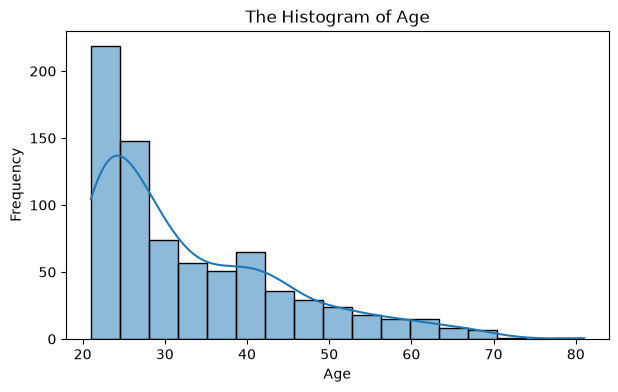

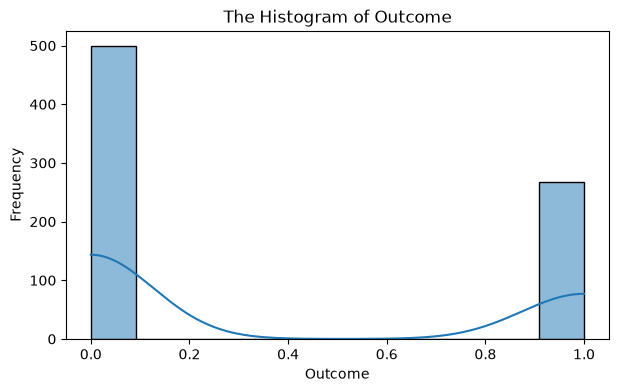

In [1363]:
#histogram
for i in df.columns:
    plt.figure(figsize=(7, 4))
    sns.histplot(data=df, x=i, kde=True)
    plt.title(f'The Histogram of {i}')
    plt.xlabel(i)
    plt.ylabel('Frequency')
    plt.show()

In [1364]:
df['Outcome'].value_counts()

Outcome
0    500
1    268
Name: count, dtype: int64

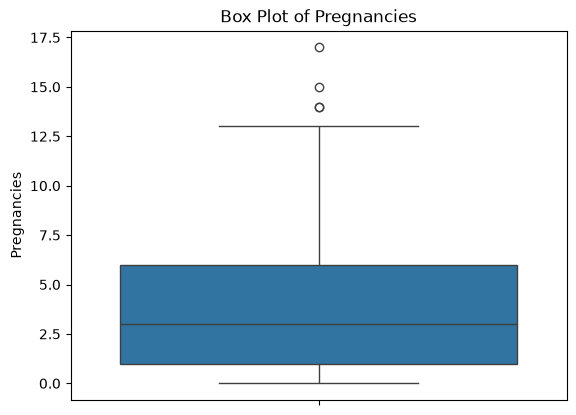

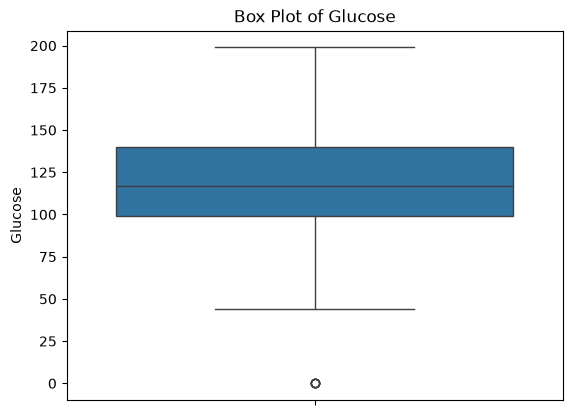

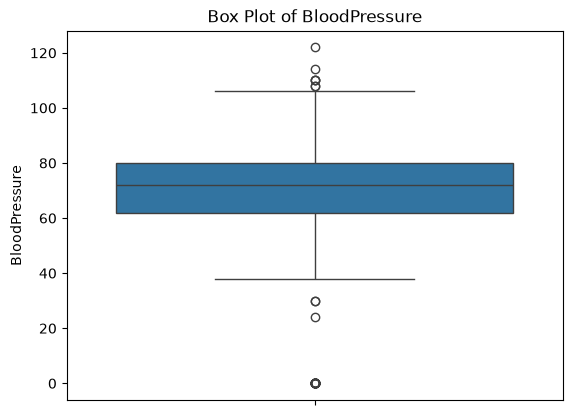

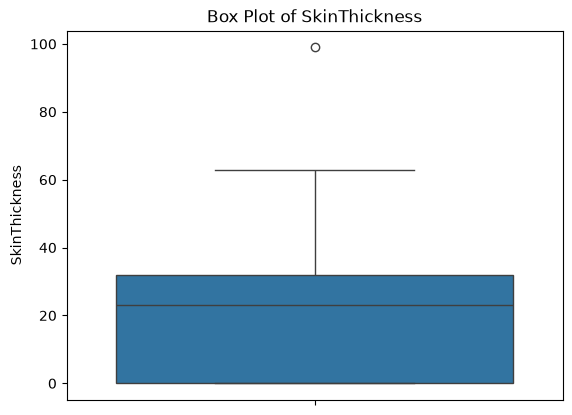

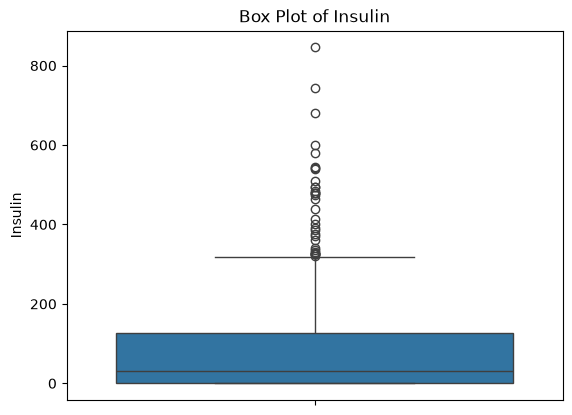

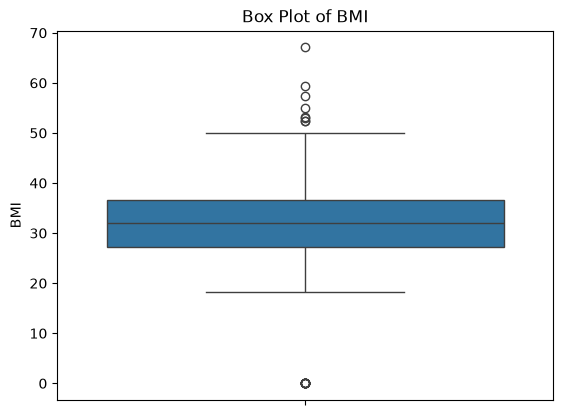

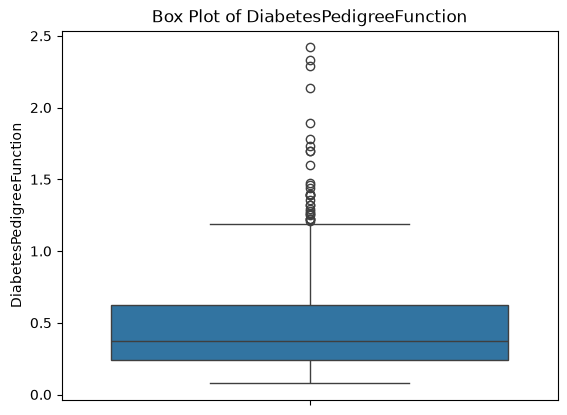

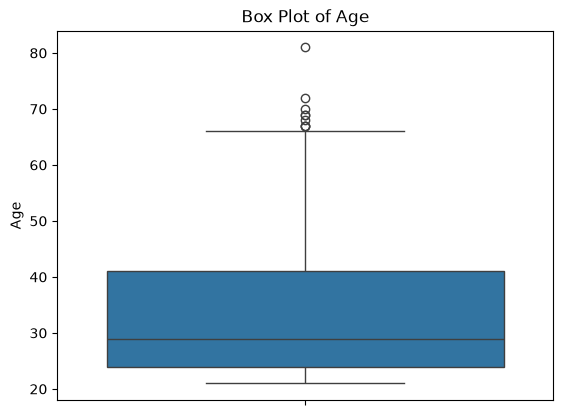

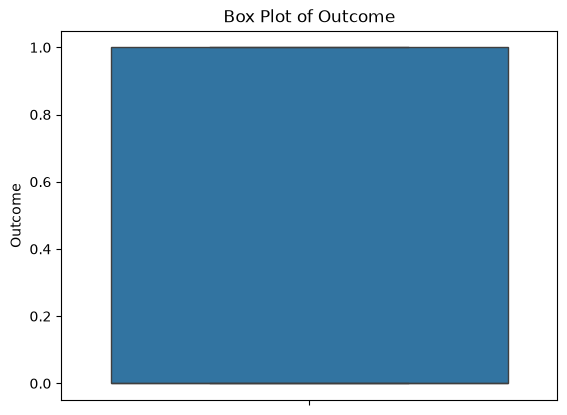

In [1365]:
#Boxplot
for col in df.select_dtypes(exclude='object').columns:
    sns.boxplot(y=df[col])
    plt.title(f'Box Plot of {col}')
    plt.show()

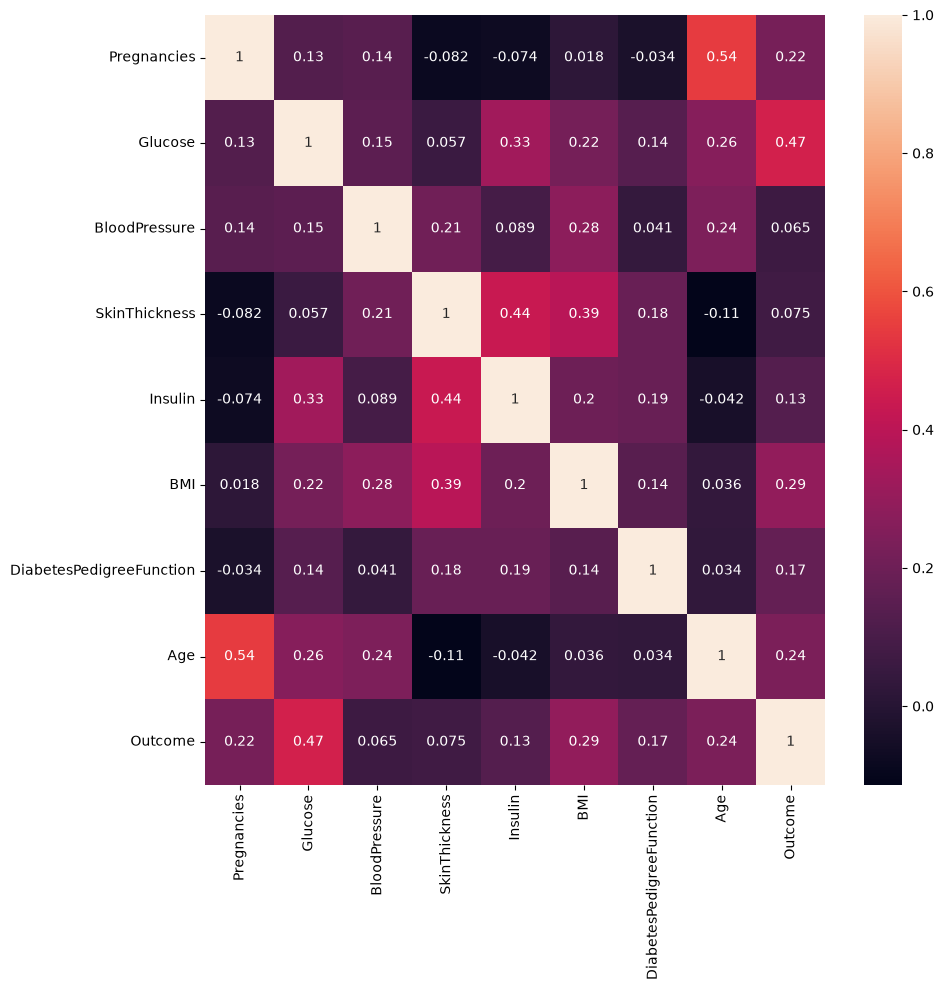

In [1366]:
#correlation heatmap
plt.figure(figsize=(10,10))
sns.heatmap(df.corr(numeric_only=True),annot=True)
plt.show()

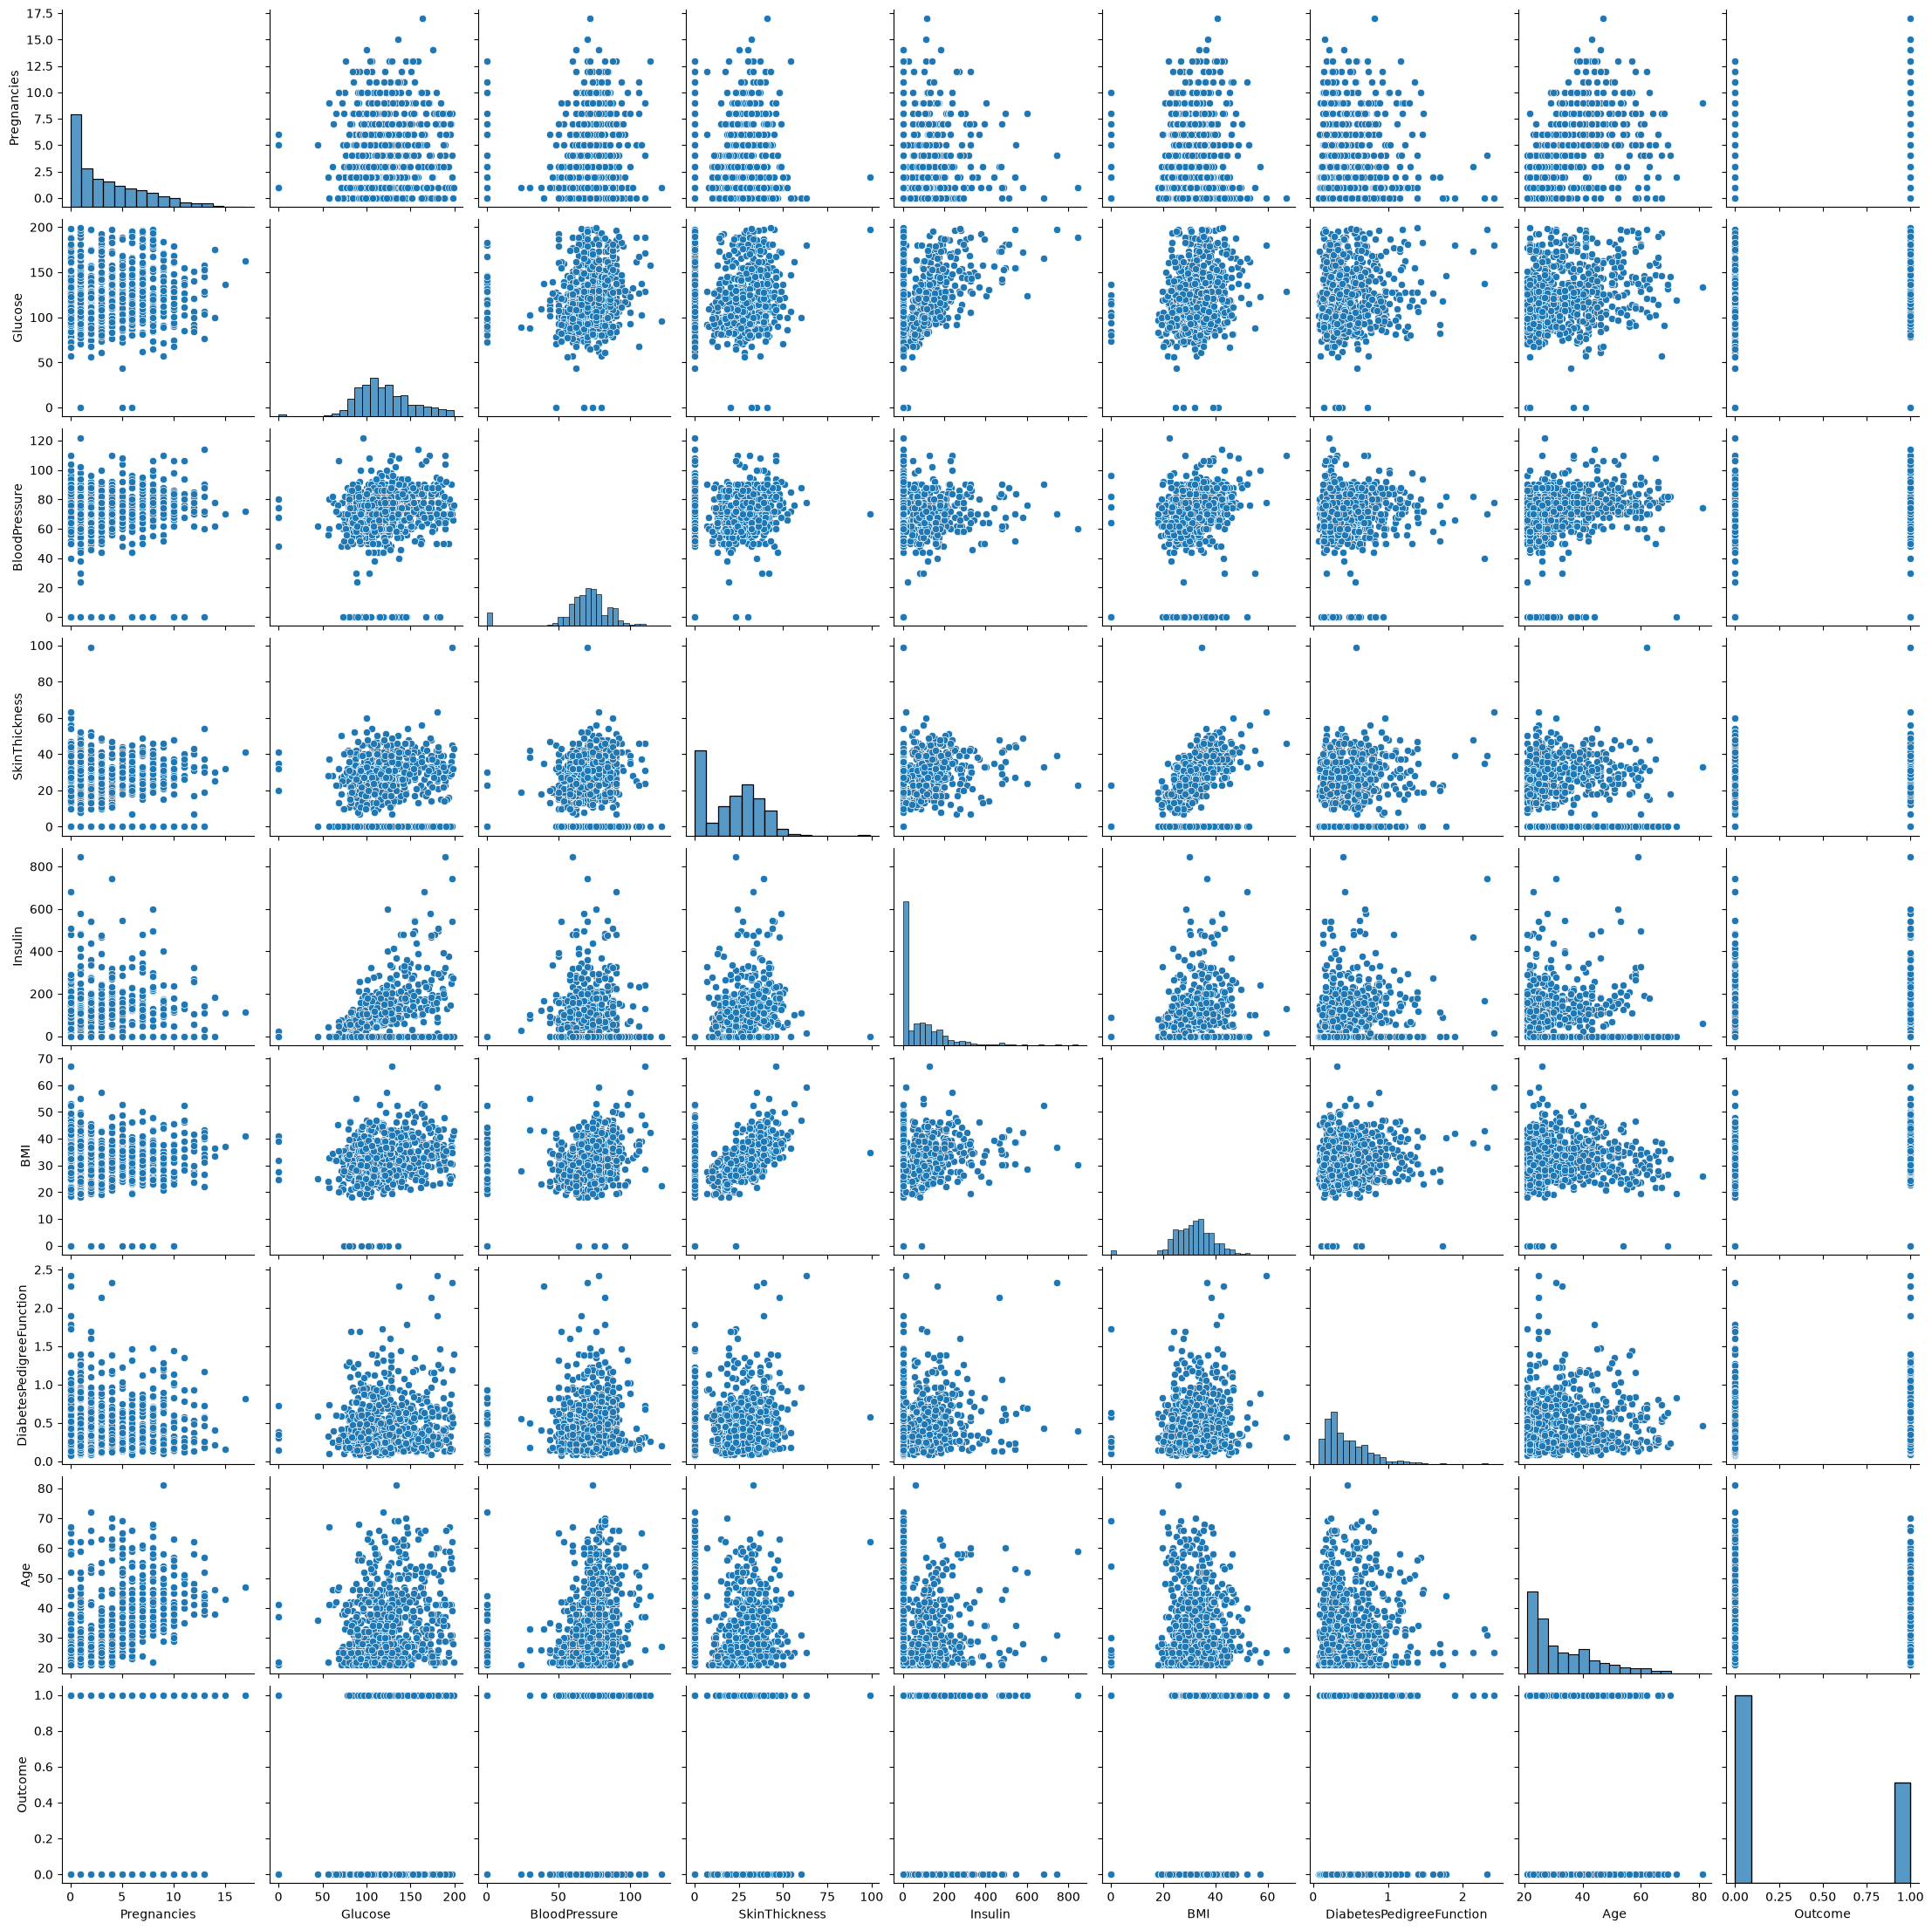

In [1367]:
#Pairplot
sns.pairplot(data=df)
plt.show()

In [1368]:
df.isnull().sum() # no null values

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [1369]:
df.duplicated().sum()  #no duplicates in the data

np.int64(0)

In [1370]:
#removing Outliers, as they were present during boxplot earlier
for col in df.select_dtypes(include= ['int64', 'float64']).columns:
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)

        iqr= q3-q1

        lower_bound = q1-1.5*iqr
        upper_bound=q3+1.5*iqr

        df[col]= df[col].clip(lower_bound,upper_bound)

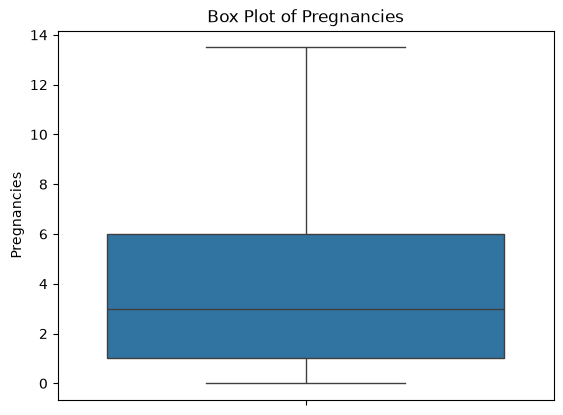

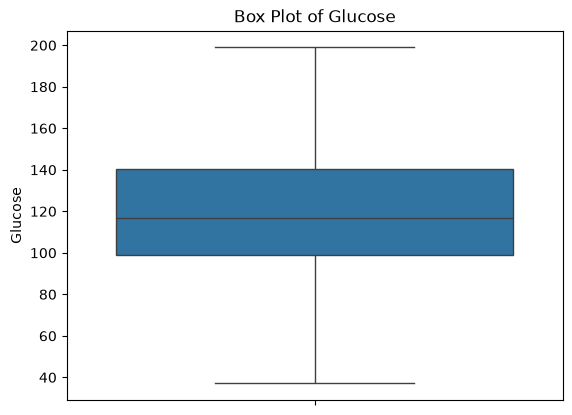

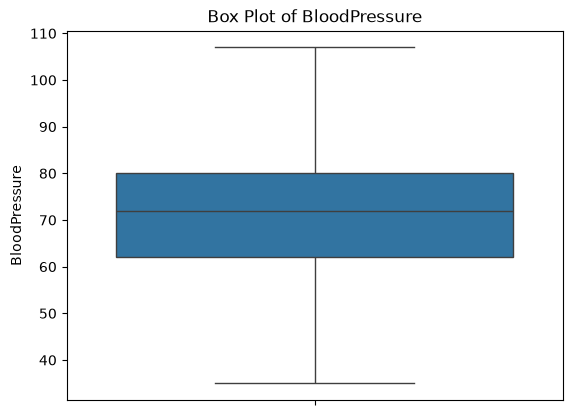

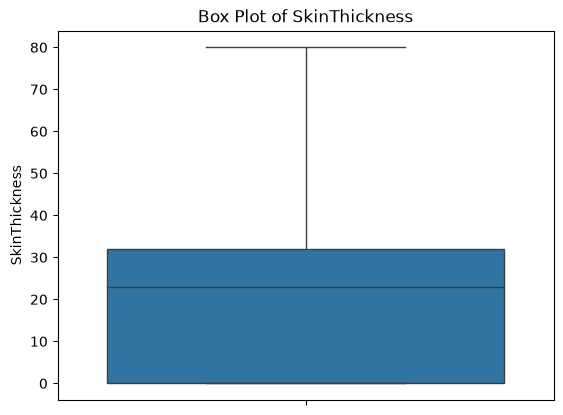

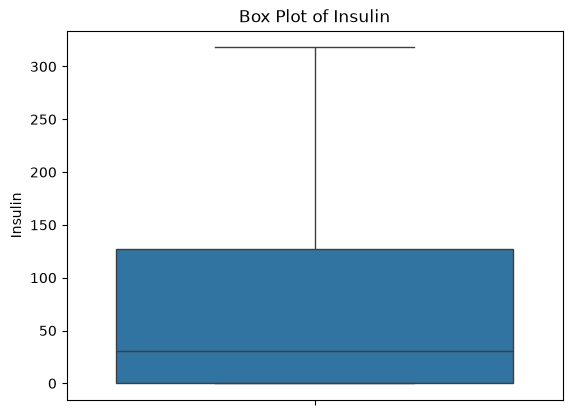

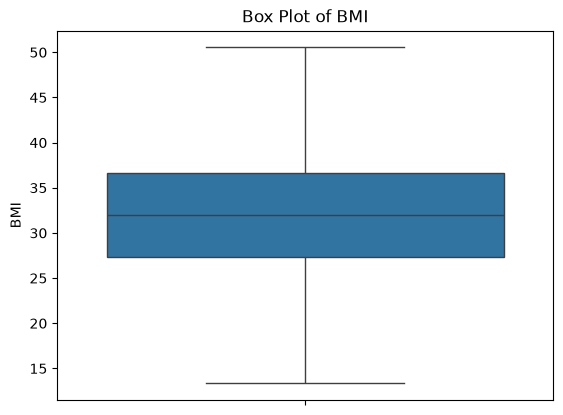

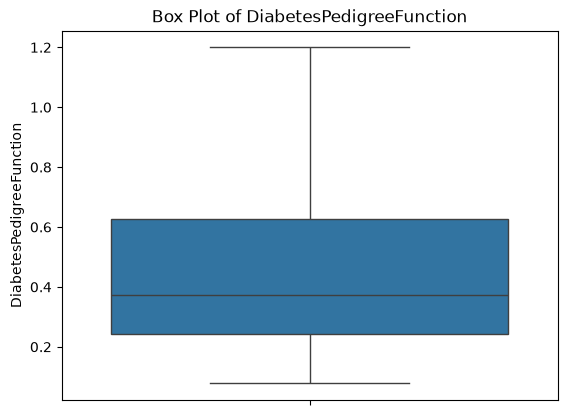

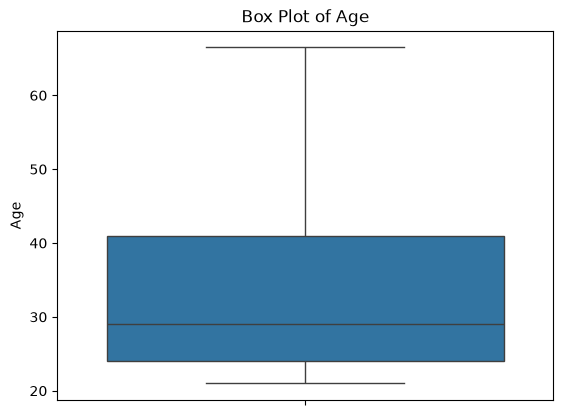

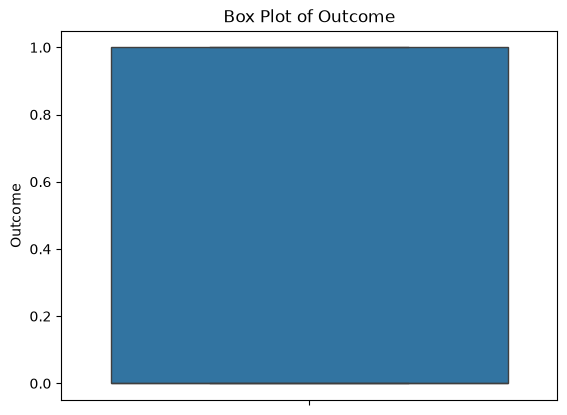

In [1371]:
#Boxplot
for col in df.select_dtypes(exclude='object').columns:
    sns.boxplot(y=df[col])
    plt.title(f'Box Plot of {col}')
    plt.show()

In [1372]:
#no catgeorical variables are present hence no encoding required.

In [1373]:
#There are rows in Skin thickness and insulin with value 0.
#As SkinThickness: Triceps skin fold thickness (mm) and Insulin: 2-Hour serum insulin (mu U/ml)- these with value 0 seems incorrect.

df[df['SkinThickness']==0]


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
2,8.0,183.0,64,0,0.0,23.30,0.672,32.0,1
5,5.0,116.0,74,0,0.0,25.60,0.201,30.0,0
7,10.0,115.0,35,0,0.0,35.30,0.134,29.0,0
9,8.0,125.0,96,0,0.0,13.35,0.232,54.0,1
10,4.0,110.0,92,0,0.0,37.60,0.191,30.0,0
...,...,...,...,...,...,...,...,...,...
757,0.0,123.0,72,0,0.0,36.30,0.258,52.0,1
758,1.0,106.0,76,0,0.0,37.50,0.197,26.0,0
759,6.0,190.0,92,0,0.0,35.50,0.278,66.0,1
762,9.0,89.0,62,0,0.0,22.50,0.142,33.0,0


In [1374]:
#Replace zero with NaN
col=['SkinThickness','Insulin']
for i in col:
    df[i] = df[i].replace(0, np.nan)

# Fill missing values with the mean
df.fillna({'SkinThickness':df.SkinThickness.mean(),'Insulin':df.Insulin.mean()}, inplace=True)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6.0,148.0,72,35.000000,143.566624,33.6,0.627,50.0,1
1,1.0,85.0,66,29.000000,143.566624,26.6,0.351,31.0,0
2,8.0,183.0,64,29.118299,143.566624,23.3,0.672,32.0,1
3,1.0,89.0,66,23.000000,94.000000,28.1,0.167,21.0,0
4,0.0,137.0,40,35.000000,168.000000,43.1,1.200,33.0,1
...,...,...,...,...,...,...,...,...,...
763,10.0,101.0,76,48.000000,180.000000,32.9,0.171,63.0,0
764,2.0,122.0,70,27.000000,143.566624,36.8,0.340,27.0,0
765,5.0,121.0,72,23.000000,112.000000,26.2,0.245,30.0,0
766,1.0,126.0,60,29.118299,143.566624,30.1,0.349,47.0,1


In [1375]:
#Using Data Transformation> to make them less right skewed
for i in df.columns:
    df[i]= np.sqrt(df[i])

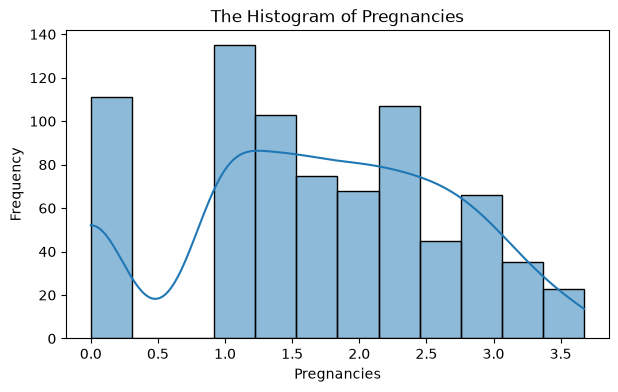

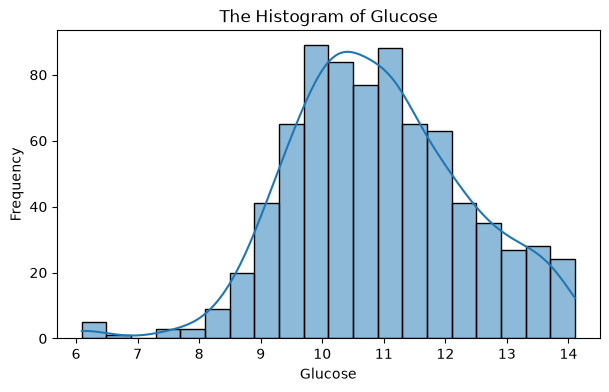

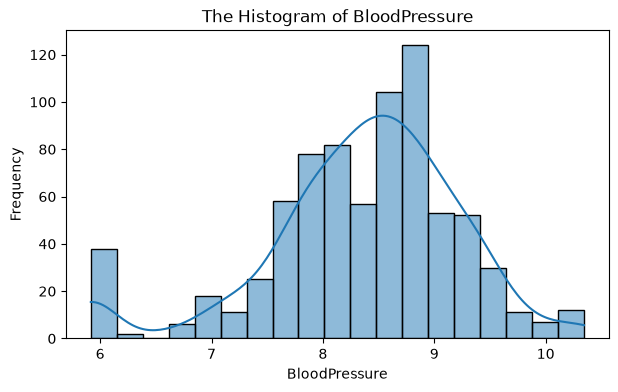

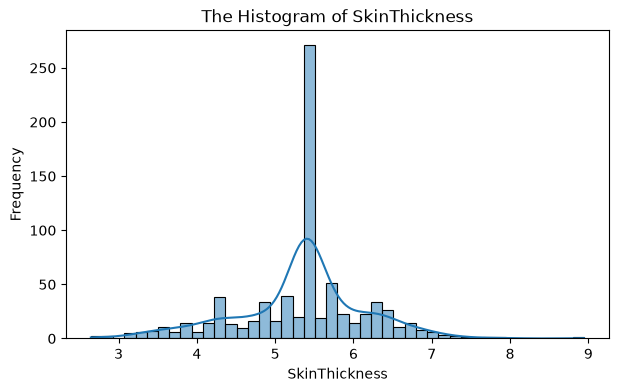

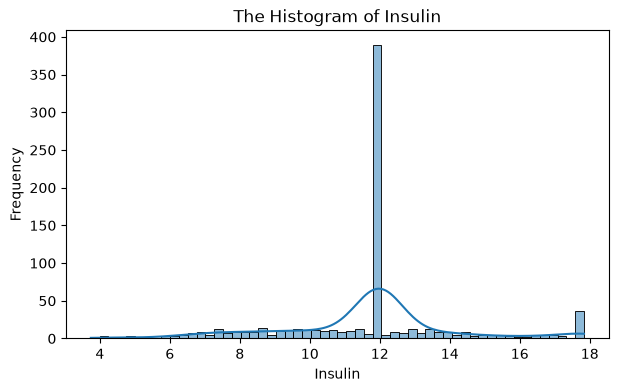

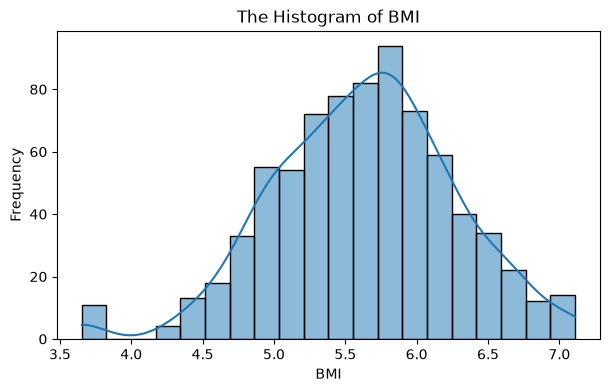

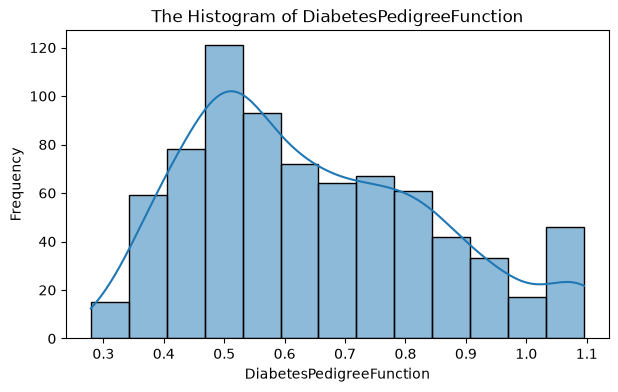

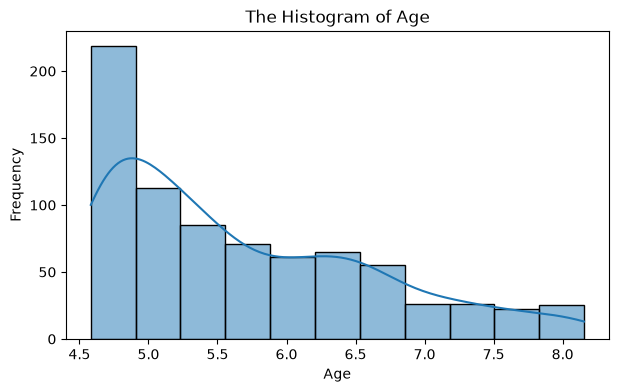

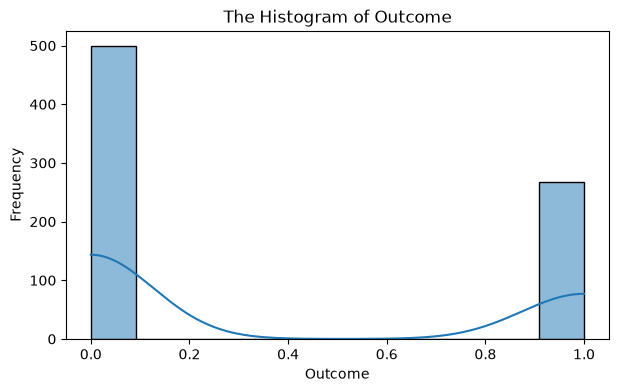

In [1376]:
#histogram
for i in df.columns:
    plt.figure(figsize=(7, 4))
    sns.histplot(data=df, x=i, kde=True)
    plt.title(f'The Histogram of {i}')
    plt.xlabel(i)
    plt.ylabel('Frequency')
    plt.show()

In [1377]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,1.694458,10.914376,8.360910,5.333916,11.716716,5.632599,0.646719,5.682380,0.348958
std,0.983519,1.419595,0.883798,0.817625,2.508663,0.631992,0.201797,0.954787,0.476951
min,0.000000,6.093029,5.916080,2.645751,3.741657,3.653765,0.279285,4.582576,0.000000
25%,1.000000,9.949874,7.874008,5.000000,11.022634,5.224940,0.493710,4.898979,0.000000
50%,1.732051,10.816654,8.485281,5.396137,11.981929,5.656854,0.610327,5.385165,0.000000
75%,2.449490,11.842705,8.944272,5.656854,11.981929,6.049793,0.791360,6.403124,1.000000
max,3.674235,14.106736,10.344080,8.944272,17.836059,7.109852,1.095445,8.154753,1.000000


In [1378]:
#Not applying standard scaling as the range of data is quite reasonable

In [1379]:
df['Outcome'].value_counts() #there is imbalance in class in the outcome, so would try for cross validation.

Outcome
0.0    500
1.0    268
Name: count, dtype: int64

In [1380]:
#Feature Selection
feat=df.drop(columns='Outcome')
tar=df['Outcome']

In [1381]:
from sklearn.feature_selection import f_classif

pd.Series(f_classif(feat,tar)[0], index=feat.columns).sort_values(ascending=False)

Glucose                     214.794650
BMI                          81.257152
Age                          56.052361
Insulin                      53.518397
SkinThickness                39.368002
DiabetesPedigreeFunction     27.119437
Pregnancies                  25.401718
BloodPressure                 8.198382
dtype: float64

In [1382]:
pd.Series(f_classif(feat,tar)[0], index=feat.columns).sort_values(ascending=False).index[0:7]

Index(['Glucose', 'BMI', 'Age', 'Insulin', 'SkinThickness',
       'DiabetesPedigreeFunction', 'Pregnancies'],
      dtype='str')

In [1383]:
#removing BloodPressure from the dataset
df1= df[['Glucose', 'BMI', 'Age', 'Insulin', 'SkinThickness','DiabetesPedigreeFunction', 'Pregnancies','Outcome']]

In [1384]:
#Train test split
x= df1.drop(columns='Outcome')
y=df1['Outcome']


from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test= train_test_split(x,y,test_size=0.2,random_state=50,stratify=df['Outcome'])


In [1385]:
#Model1- Logistic Regression
from sklearn.linear_model import LogisticRegression
lr1 = LogisticRegression(max_iter=500,class_weight='balanced')
lr1.fit(x_train, y_train)

pred_train = lr1.predict(x_train)
pred_test = lr1.predict(x_test)

In [1386]:
from sklearn.metrics  import *

print("Train Acc is ",accuracy_score(y_train,pred_train))
print(classification_report(y_train,pred_train))
print('\n')
print("Test Acc is ",accuracy_score(y_test,pred_test))
print(classification_report(y_test,pred_test))

Train Acc is  0.754071661237785
              precision    recall  f1-score   support

         0.0       0.85      0.76      0.80       400
         1.0       0.62      0.75      0.68       214

    accuracy                           0.75       614
   macro avg       0.74      0.75      0.74       614
weighted avg       0.77      0.75      0.76       614



Test Acc is  0.7402597402597403
              precision    recall  f1-score   support

         0.0       0.82      0.77      0.79       100
         1.0       0.62      0.69      0.65        54

    accuracy                           0.74       154
   macro avg       0.72      0.73      0.72       154
weighted avg       0.75      0.74      0.74       154



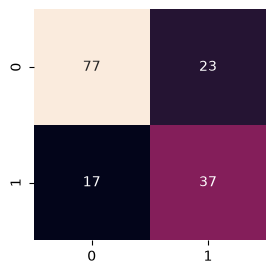

In [1387]:
#For Testing data
cm = confusion_matrix(y_test,pred_test)
plt.figure(figsize=(3,3))
sns.heatmap(cm,cbar=False,annot=True,fmt='d') #d means decimal
plt.show()

In [1388]:
#to get sigmoid values
sigmoid = lr.predict_proba(x_test)[:,1]

from sklearn.metrics import roc_auc_score,roc_curve

auc_score = roc_auc_score(y_test,sigmoid)
auc_score

0.7957407407407407

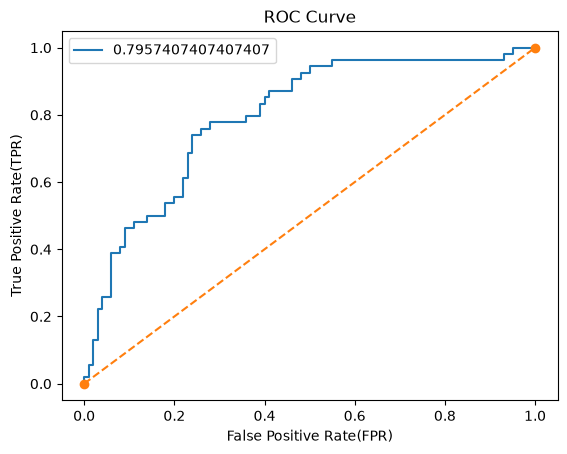

In [1389]:
fpr, tpr,thr = roc_curve(y_test,sigmoid)


plt.plot(fpr,tpr,label = f'{auc_score}')
plt.plot([0,1],[0,1],'o--')
plt.xlabel('False Positive Rate(FPR)')
plt.ylabel('True Positive Rate(TPR)')
plt.title('ROC Curve')
plt.legend()
plt.show()


In [1390]:
# Find coefficients
coefficients = pd.DataFrame({
    'Feature': x_train.columns,
    'Coefficient': lr1.coef_[0]
})

print(coefficients.sort_values(by='Coefficient',ascending=False))

# Find intercept
print("Intercept:", lr1.intercept_)

                    Feature  Coefficient
5  DiabetesPedigreeFunction     1.205016
1                       BMI     0.843450
0                   Glucose     0.783286
2                       Age     0.410993
6               Pregnancies     0.257351
4             SkinThickness     0.058709
3                   Insulin     0.023894
Intercept: [-17.7686662]


In [1391]:
#model 2 - Logistic Regression with Scaling

from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
# Fit scaler only on training data, then transform
x_train_scaled = sc.fit_transform(x_train)
x_test_scaled = sc.transform(x_test)

from sklearn.linear_model import LogisticRegression
lr2 = LogisticRegression(max_iter=500,class_weight='balanced')
lr2.fit(x_train_scaled, y_train)

pred_train = lr2.predict(x_train_scaled)
pred_test = lr2.predict(x_test_scaled)



In [1392]:
from sklearn.metrics  import *

print("Train Acc is ",accuracy_score(y_train,pred_train))
print(classification_report(y_train,pred_train))
print('\n')
print("Test Acc is ",accuracy_score(y_test,pred_test))
print(classification_report(y_test,pred_test))

Train Acc is  0.750814332247557
              precision    recall  f1-score   support

         0.0       0.85      0.75      0.80       400
         1.0       0.62      0.75      0.68       214

    accuracy                           0.75       614
   macro avg       0.73      0.75      0.74       614
weighted avg       0.77      0.75      0.76       614



Test Acc is  0.7402597402597403
              precision    recall  f1-score   support

         0.0       0.83      0.76      0.79       100
         1.0       0.61      0.70      0.66        54

    accuracy                           0.74       154
   macro avg       0.72      0.73      0.72       154
weighted avg       0.75      0.74      0.74       154



In [1393]:
#to get sigmoid values
sigmoid = lr2.predict_proba(x_test_scaled)[:,1]

from sklearn.metrics import roc_auc_score,roc_curve

auc_score = roc_auc_score(y_test,sigmoid)
auc_score

0.797037037037037

In [1394]:
#Model3- Logistic Regression with scaling and Stratified K-Folds, cv=3

lr3=LogisticRegressionCV(cv=3,max_iter=500,class_weight='balanced')

lr3.fit(x_train_scaled,y_train)

pred_train=lr3.predict(x_train_scaled)

pred_test=lr3.predict(x_test_scaled)

In [1395]:
from sklearn.metrics  import *

print("Train Acc is ",accuracy_score(y_train,pred_train))
print(classification_report(y_train,pred_train))
print('\n')
print("Test Acc is ",accuracy_score(y_test,pred_test))
print(classification_report(y_test,pred_test))

Train Acc is  0.750814332247557
              precision    recall  f1-score   support

         0.0       0.85      0.75      0.80       400
         1.0       0.62      0.75      0.68       214

    accuracy                           0.75       614
   macro avg       0.73      0.75      0.74       614
weighted avg       0.77      0.75      0.76       614



Test Acc is  0.7402597402597403
              precision    recall  f1-score   support

         0.0       0.83      0.76      0.79       100
         1.0       0.61      0.70      0.66        54

    accuracy                           0.74       154
   macro avg       0.72      0.73      0.72       154
weighted avg       0.75      0.74      0.74       154



In [1396]:
#to get sigmoid values
sigmoid = lr3.predict_proba(x_test_scaled)[:,1]

from sklearn.metrics import roc_auc_score,roc_curve

auc_score = roc_auc_score(y_test,sigmoid)
auc_score

0.797962962962963

In [1397]:
#Choosing model1- Logistic Regression 

In [1398]:
import joblib
joblib.dump(lr, "model.pkl")

['model.pkl']

In [1399]:
#Save scaler # as no scaling for model1 is done this file is not needed
#joblib.dump(sc, "scaler.pkl")

In [1400]:
coefficients = pd.DataFrame({
    'Feature': x_train.columns,
    'Coefficient': lr.coef_[0]
})
coefficients

,Feature,Coefficient
0,Glucose,0.783286
1,BMI,0.843450
2,Age,0.410993
3,Insulin,0.023894
4,SkinThickness,0.058709
5,DiabetesPedigreeFunction,1.205016
6,Pregnancies,0.257351


In [1401]:
df1[df1.Outcome==0].head()

,Glucose,BMI,Age,Insulin,SkinThickness,DiabetesPedigreeFunction,Pregnancies,Outcome
1,9.219544,5.157519,5.567764,11.981929,5.385165,0.592453,1.000000,0.0
3,9.433981,5.300943,4.582576,9.695360,4.795832,0.408656,1.000000,0.0
5,10.770330,5.059644,5.477226,11.981929,5.396137,0.448330,2.236068,0.0
7,10.723805,5.941380,5.385165,11.981929,5.396137,0.366060,3.162278,0.0
10,10.488088,6.131884,5.477226,11.981929,5.396137,0.437035,2.000000,0.0


In [1402]:
df1[df1.Outcome==1].head()

,Glucose,BMI,Age,Insulin,SkinThickness,DiabetesPedigreeFunction,Pregnancies,Outcome
0,12.165525,5.796551,7.071068,11.981929,5.916080,0.791833,2.449490,1.0
2,13.527749,4.827007,5.656854,11.981929,5.396137,0.819756,2.828427,1.0
4,11.704700,6.565059,5.744563,12.961481,5.916080,1.095445,0.000000,1.0
6,8.831761,5.567764,5.099020,9.380832,5.656854,0.497996,1.732051,1.0
8,14.035669,5.522681,7.280110,17.836059,6.708204,0.397492,1.414214,1.0


In [1403]:
lr.predict([[11.704700,6.565059,5.744563,12.961481,5.916080,1.095445,0.000000]])

array([1.])

In [1404]:
#link- https://diabetespredictionfeba.streamlit.app/